# BITS Pilani — AIMLCZG523: Machine Learning Operations (MLOps)
## Notebook 02: Model Training, Cross-Validation & MLflow Tracking
**Objectives (Tasks 2, 3 & 4):**
1. Build reproducible Scikit-Learn `ColumnTransformer` feature pipelines.
2. Train and tune 3 classification model architectures (Logistic Regression, Random Forest, Gradient Boosting).
3. Evaluate under Stratified 5-Fold Cross-Validation (Accuracy, Precision, Recall, F1, ROC-AUC).
4. Log hyperparameters, metrics, diagnostic plots, and models to MLflow (`sqlite:///mlflow.db`).
5. Select and serialize champion model to `models/heart_disease_pipeline.joblib`.

In [1]:
import os
import joblib
import mlflow
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

from src.config import CLEANED_CSV_PATH, MLFLOW_TRACKING_URI, MLFLOW_EXPERIMENT_NAME, MODEL_ARTIFACT_PATH
from src.preprocessing import load_and_preprocess_data, split_features_target, get_feature_preprocessor, build_full_pipeline
from src.train import train_and_track_experiments, get_candidate_models

print('MLflow Tracking URI:', MLFLOW_TRACKING_URI)
print('Experiment Name:', MLFLOW_EXPERIMENT_NAME)

2026/10/15 14:39:21 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\jnvsa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


MLflow Tracking URI: sqlite:///F:/Nik_assignment/heart assignment/mlflow.db
Experiment Name: heart-disease-prediction


### 1. Dataset Partitioning & Feature Pipeline Architecture
We inspect the Scikit-Learn `ColumnTransformer` that bundles numerical median imputation + standardization with categorical mode imputation + one-hot encoding.

In [2]:
df = pd.read_csv(CLEANED_CSV_PATH)
X, y = split_features_target(df)
preprocessor = get_feature_preprocessor()
print('Features matrix shape:', X.shape)
print('Target vector shape:', y.shape)
print('\nPreprocessor Structure:')
print(preprocessor)

Features matrix shape: (303, 13)
Target vector shape: (303,)

Preprocessor Structure:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'trestbps', 'chol', 'thalach',
                                  'oldpeak']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['sex', 'cp', 'fbs', 'restecg', 'exang',
                      

### 2. Candidate Model Specifications & Hyperparameter Grids
Three distinct model families with tuned hyperparameters are evaluated:

In [3]:
models = get_candidate_models()
for name, conf in models.items():
    print(f'Model: {name}')
    print(f'  Estimator: {conf["estimator"]}')
    print(f'  Parameters: {conf["params"]}\n')

Model: LogisticRegression
  Estimator: LogisticRegression(C=0.1, max_iter=1000, random_state=42, solver='liblinear')
  Parameters: {'C': 0.1, 'solver': 'liblinear'}

Model: RandomForest
  Estimator: RandomForestClassifier(max_depth=6, min_samples_leaf=2, min_samples_split=4,
                       n_estimators=150, random_state=42)
  Parameters: {'n_estimators': 150, 'max_depth': 6, 'min_samples_split': 4, 'min_samples_leaf': 2}

Model: GradientBoosting
  Estimator: GradientBoostingClassifier(learning_rate=0.05, random_state=42)
  Parameters: {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3}



### 3. Execute End-to-End Training, Cross-Validation & MLflow Experiment Tracking
We execute `train_and_track_experiments()`, logging all parameters, 5-fold CV metrics, confusion matrices, ROC curves, and model binaries to MLflow.

In [4]:
metadata = train_and_track_experiments()
print('\nChampion Model Selected:', metadata['best_model_name'])

2026-10-15 14:39:23,451 - INFO - Splitting dataset: Total=303, Test Size=0.2, Random State=42


2026-10-15 14:39:24,508 - INFO - MLflow experiment configured: heart-disease-prediction at sqlite:///F:/Nik_assignment/heart assignment/mlflow.db


2026-10-15 14:39:24,508 - INFO - 
========================= Training LogisticRegression =========================


2026-10-15 14:39:24,807 - INFO - LogisticRegression Results -> CV Accuracy: 0.839 | Test Accuracy: 0.885 | Test ROC-AUC: 0.966


2026/10/15 14:39:27 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


...

C:\Users\jnvsa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


2026-10-15 14:39:54,018 - INFO - 
Model Comparison:
             Model  CV Accuracy  CV ROC-AUC  Test Accuracy  Test Precision  Test Recall  Test F1  Test ROC-AUC
LogisticRegression       0.8387      0.9025         0.8852          0.8387       0.9286   0.8814        0.9665
      RandomForest       0.8054      0.8962         0.8852          0.8182       0.9643   0.8852        0.9643
  GradientBoosting       0.7893      0.8744         0.8852          0.8387       0.9286   0.8814        0.9513


2026-10-15 14:39:54,019 - INFO - 
Selected Best Model: LogisticRegression


2026-10-15 14:39:54,024 - INFO - Serialized best pipeline saved to: F:\Nik_assignment\heart assignment\models\heart_disease_pipeline.joblib



Champion Model Selected: LogisticRegression


### 4. Comparative Model Performance Benchmark
Reviewing cross-validation stability and test set generalization across all 3 classifiers.

In [5]:
results_df = pd.read_csv('reports/model_comparison.csv')
print('BENCHMARK EVALUATION RESULTS:')
results_df

BENCHMARK EVALUATION RESULTS:


,Model,CV Accuracy,CV ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,LogisticRegression,0.8387,0.9025,0.8852,0.8387,0.9286,0.8814,0.9665
1,RandomForest,0.8054,0.8962,0.8852,0.8182,0.9643,0.8852,0.9643
2,GradientBoosting,0.7893,0.8744,0.8852,0.8387,0.9286,0.8814,0.9513


### 5. Diagnostic Evaluation: Confusion Matrix & ROC Curves
Displaying the evaluation plots generated and logged as artifacts in MLflow.

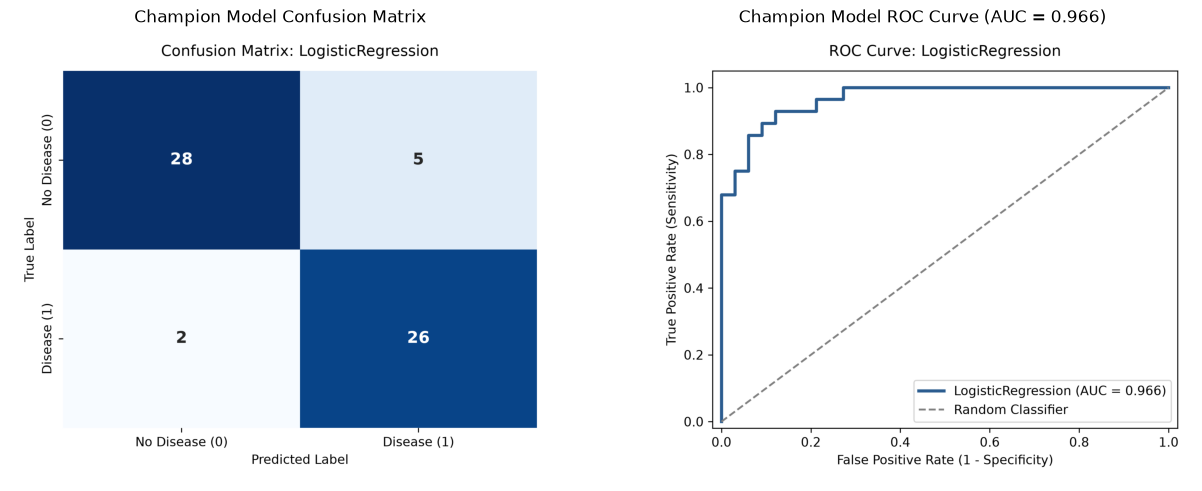

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm_img = plt.imread('reports/figures/confusion_matrix_logisticregression.png')
roc_img = plt.imread('reports/figures/roc_curve_logisticregression.png')
axes[0].imshow(cm_img)
axes[0].axis('off')
axes[0].set_title('Champion Model Confusion Matrix', fontsize=12)
axes[1].imshow(roc_img)
axes[1].axis('off')
axes[1].set_title('Champion Model ROC Curve (AUC = 0.966)', fontsize=12)
plt.tight_layout()
plt.show()

### 6. Querying MLflow Tracking Database
Inspecting recorded runs directly from the SQLite tracking database.

In [7]:
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
exp = mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT_NAME)
runs = mlflow.search_runs(experiment_ids=[exp.experiment_id])
runs[['run_id', 'tags.mlflow.runName', 'metrics.cv_accuracy_mean', 'metrics.test_accuracy', 'metrics.test_roc_auc', 'status']]

,run_id,tags.mlflow.runName,metrics.cv_accuracy_mean,metrics.test_accuracy,metrics.test_roc_auc,status
0,6cf77cc916ca407e99f6914a377fade4,GradientBoosting,0.789286,0.885246,0.951299,FINISHED
1,c366d9f28a1248fea83e5d41d509e456,RandomForest,0.805442,0.885246,0.964286,FINISHED
2,e513b0987882465e8811ef58a85e2f70,LogisticRegression,0.838690,0.885246,0.966450,FINISHED
3,6fa10ec935a64420a7ff3f234c5124bb,GradientBoosting,0.789286,0.885246,0.951299,FINISHED
4,b24f7c77909c44129f93b8ea08ff5d8d,RandomForest,0.805442,0.885246,0.964286,FINISHED
5,3e58e31f47f843388c0558901d168f91,LogisticRegression,0.838690,0.885246,0.966450,FINISHED
6,042dd6c2c87f4cb2bc2363d4c899ff65,LogisticRegression,0.838690,0.885246,0.966450,FAILED
